In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity


# Análise Exploratória dos Dados (EDA) - GestaltMatcher Dataset

Neste notebook carregamos o arquivo pickle `mini_gm_public_v0.1.p` e analisamos a relação entre as **Síndromes** e a quantidade de **Imagens** / **Sujeitos**.

## Carregando os dados brutos

In [19]:
import pandas as pd
# 1. Carregar os dados
data = pd.read_pickle("raw_data/mini_gm_public_v0.1.p")

rows = []
for key1, level2 in data.items():
    for key2, level3 in level2.items():
        for key3, vector in level3.items():
            rows.append({
                "subject_id": key1,
                "syndrome_id": key2,
                "embedding": vector
            })

df = pd.DataFrame(rows) 

df_explode = df.explode('embedding')

print(df_explode)

     subject_id syndrome_id embedding
0     300000082         595  -0.03718
0     300000082         595  1.741486
0     300000082         595  1.206103
0     300000082         595 -0.451453
0     300000082         595 -0.736373
...         ...         ...       ...
1115  300000007      739895  1.074383
1115  300000007      739895 -2.169581
1115  300000007      739895 -0.450305
1115  300000007      739895 -0.292951
1115  300000007      739895 -1.008367

[357120 rows x 3 columns]


Agora, vamos descrever os dados para verificar a quantidade total de linhas, valores únicos e a frequência que esses dados aparecem

In [20]:
df_explode.describe()

,subject_id,syndrome_id,embedding
count,357120,357120,357120.000000
unique,10,941,356081.000000
top,300000034,8980,0.663996
freq,67200,3520,3.000000


Verificando a quantidade de vezes que cada síndrome aparece no dataset

In [31]:
df_explode['subject_id'].value_counts()

subject_id
300000034    67200
300000080    63360
100192430    43520
300000007    36800
300000082    31360
100610443    28480
300000018    23680
100180860    21440
100610883    20800
700018215    20480
Name: count, dtype: int64

Verificando o tipo dos dados

In [32]:
df_explode.info()

<class 'pandas.DataFrame'>
Index: 357120 entries, 0 to 1115
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   subject_id   357120 non-null  str   
 1   syndrome_id  357120 non-null  str   
 2   embedding    357120 non-null  object
dtypes: object(1), str(2)
memory usage: 10.9+ MB


## Tratamento dos dados

Não existem dados nulos nesse dataset. Por isso não é necessário realizar uma substituição ou apagar alguma linha

In [36]:
df_explode.isnull().sum()

subject_id     0
syndrome_id    0
embedding      0
dtype: int64

## Generalizando o scatterplot para as outras síndromes

Vamos pegar uma amostra do dataset, umas 150 linhas,  vamos aplivar o t-SNE para fazer o agrupamento não linear dos dados e depois visualizar os dados usando o scatterplot

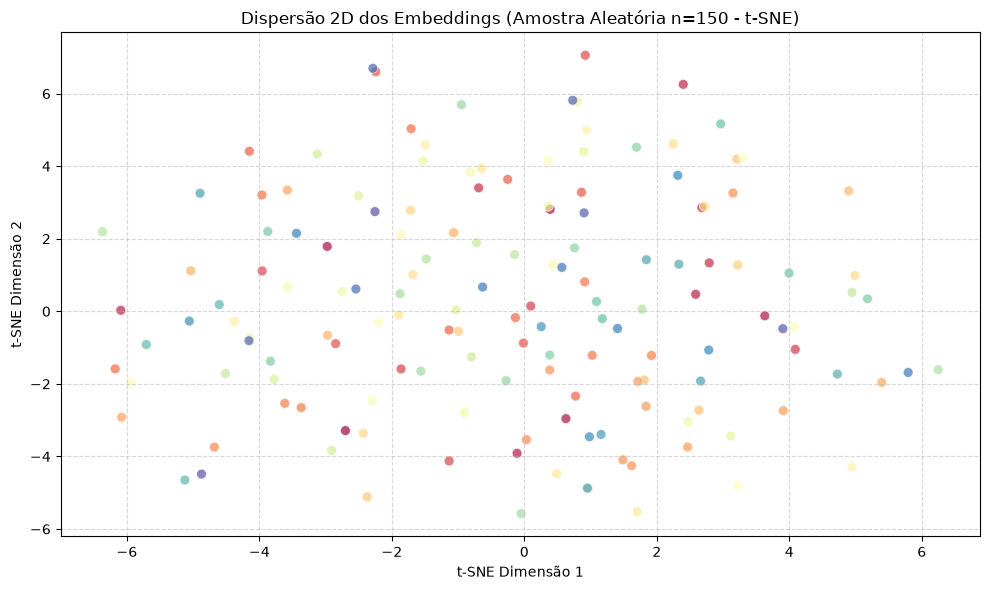

In [ ]:

df_sample = df.sample(n=150, random_state=42).copy()

X_sample = np.vstack(df_sample['embedding'].values)
y_sample = df_sample['syndrome_id'].values
# 3. Aplicar t-SNE (ótimo para capturar agrupamentos não lineares)
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_2d = tsne.fit_transform(X_sample)
# 4. DataFrame auxiliar
df_plot = pd.DataFrame({
    'tSNE_1': X_2d[:, 0],
    'tSNE_2': X_2d[:, 1],
    'syndrome_id': y_sample
})
# 5. Gerar o Scatterplot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_plot,
    x='tSNE_1',
    y='tSNE_2',
    hue='syndrome_id',
    palette='Spectral',
    legend=False,  # Legenda desativada pois há muitas classes na amostra aleatória
    alpha=0.7,
    s=50
)
plt.title('Dispersão 2D dos Embeddings (Amostra Aleatória n=150 - t-SNE)')
plt.xlabel('t-SNE Dimensão 1')
plt.ylabel('t-SNE Dimensão 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

A partir dessa amostra, verificamos que os embeddings estão bem próximos um dos outros, facilitando assim a aplicação do KNN

## Montando o Pipeline

In [38]:
from sklearn.pipeline import Pipeline 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="median")),
    ('std_scaler', StandardScaler()) 
]) 


df_prepared = num_pipeline.fit_transform(df_explode[['embedding']])

## Aplicando a tranformação nas colunas categóricas

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

num_attribs = ['embedding']
cat_attribs = ['syndrome_id', 'embedding'] 

full_pipeline = ColumnTransformer([ 
    ("num", num_pipeline, num_attribs),
    ("cat", OneHotEncoder(), cat_attribs)
]) 

df_prepared = full_pipeline.fit_transform(df_explode)

## Dividindo os dados entre treino e teste

In [48]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import Normalizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import top_k_accuracy_score
# 1. Carregar e filtrar síndromes que têm pelo menos 2 amostras
# (Garante que haverá pelo menos 1 amostra no treino e 1 no teste)
counts = df_explode['syndrome_id'].value_counts()
syndromes_validas = counts[counts >= 2].index
df_filtered = df_explode[df_explode['syndrome_id'].isin(syndromes_validas)].copy()
X = np.vstack(df_filtered['embedding'].values)
y = df_filtered['syndrome_id'].values
# 2. Normalizar os embeddings (L2 Norm para Similaridade de Cosseno)
normalizer = Normalizer(norm='l2')
X_norm = normalizer.fit_transform(X)
# 3. Divisão Treino e Teste Estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X_norm, y, test_size=0.3, random_state=42, stratify=y
)


## Criando o pipeline e implementando o knn

In [49]:
knn = KNeighborsClassifier(n_neighbors=1, metric='cosine')
knn.fit(X_train, y_train)
# 5. Previsões e Probabilidades
y_pred = knn.predict(X_test)
y_proba = knn.predict_proba(X_test)
# 6. Avaliação em Top-1, Top-5 e Top-10
top1 = knn.score(X_test, y_test)
top5 = top_k_accuracy_score(y_test, y_proba, k=5)
top10 = top_k_accuracy_score(y_test, y_proba, k=10)
print(f"Número de classes avaliadas: {len(np.unique(y))}")
print(f"Acurácia Top-1 (Exata):     {top1 * 100:.2f}%")
print(f"Acurácia Top-5 (no Top 5):   {top5 * 100:.2f}%")
print(f"Acurácia Top-10 (no Top 10): {top10 * 100:.2f}%")

Número de classes avaliadas: 941
Acurácia Top-1 (Exata):     0.15%
Acurácia Top-5 (no Top 5):   0.59%
Acurácia Top-10 (no Top 10): 1.22%
